# Diabetes Prediction using Machine Learning

**Goal:** Build a classification model that predicts whether a patient is likely to have diabetes (`Outcome` = 1) from medical attributes.

**Workflow:** Data loading → Exploratory Data Analysis (EDA) → Data cleaning → Train/test split → Preprocessing → Logistic Regression → Evaluation (Accuracy, F1-Score, plus Precision/Recall and Confusion Matrix) → Performance analysis.

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Part 1 — Data Preparation
### 2.1 Load the dataset

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 2.2 Exploration: shape, columns, data types, missing values, statistics

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values (NaN) per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (768, 9)

Column names: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


**Observation:** The file has no `NaN` values, but several medical columns contain `0`, which is physiologically impossible for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI`. These zeros are placeholders for missing measurements. The zero counts are checked below.

In [11]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_cols] == 0).sum().rename("zero_count")
zero_counts_df = pd.concat([zero_counts, (zero_counts / len(df) * 100).round(2).rename("zero_pct")], axis=1)
zero_counts_df

,zero_count,zero_pct
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


### 2.3 Target variable and class balance

Outcome
No diabetes (0)    500
Diabetes (1)       268
Name: count, dtype: int64


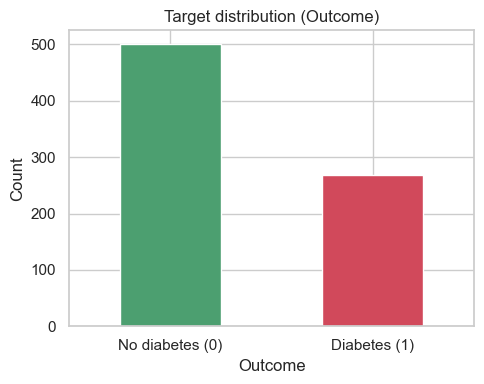

In [12]:
print(df["Outcome"].value_counts().rename({0: "No diabetes (0)", 1: "Diabetes (1)"}))
ax = df["Outcome"].value_counts().sort_index().plot(kind="bar", color=["#4C9F70", "#D1495B"], figsize=(5, 4))
ax.set_xticklabels(["No diabetes (0)", "Diabetes (1)"], rotation=0)
ax.set_title("Target distribution (Outcome)")
ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

### 2.4 Feature distributions

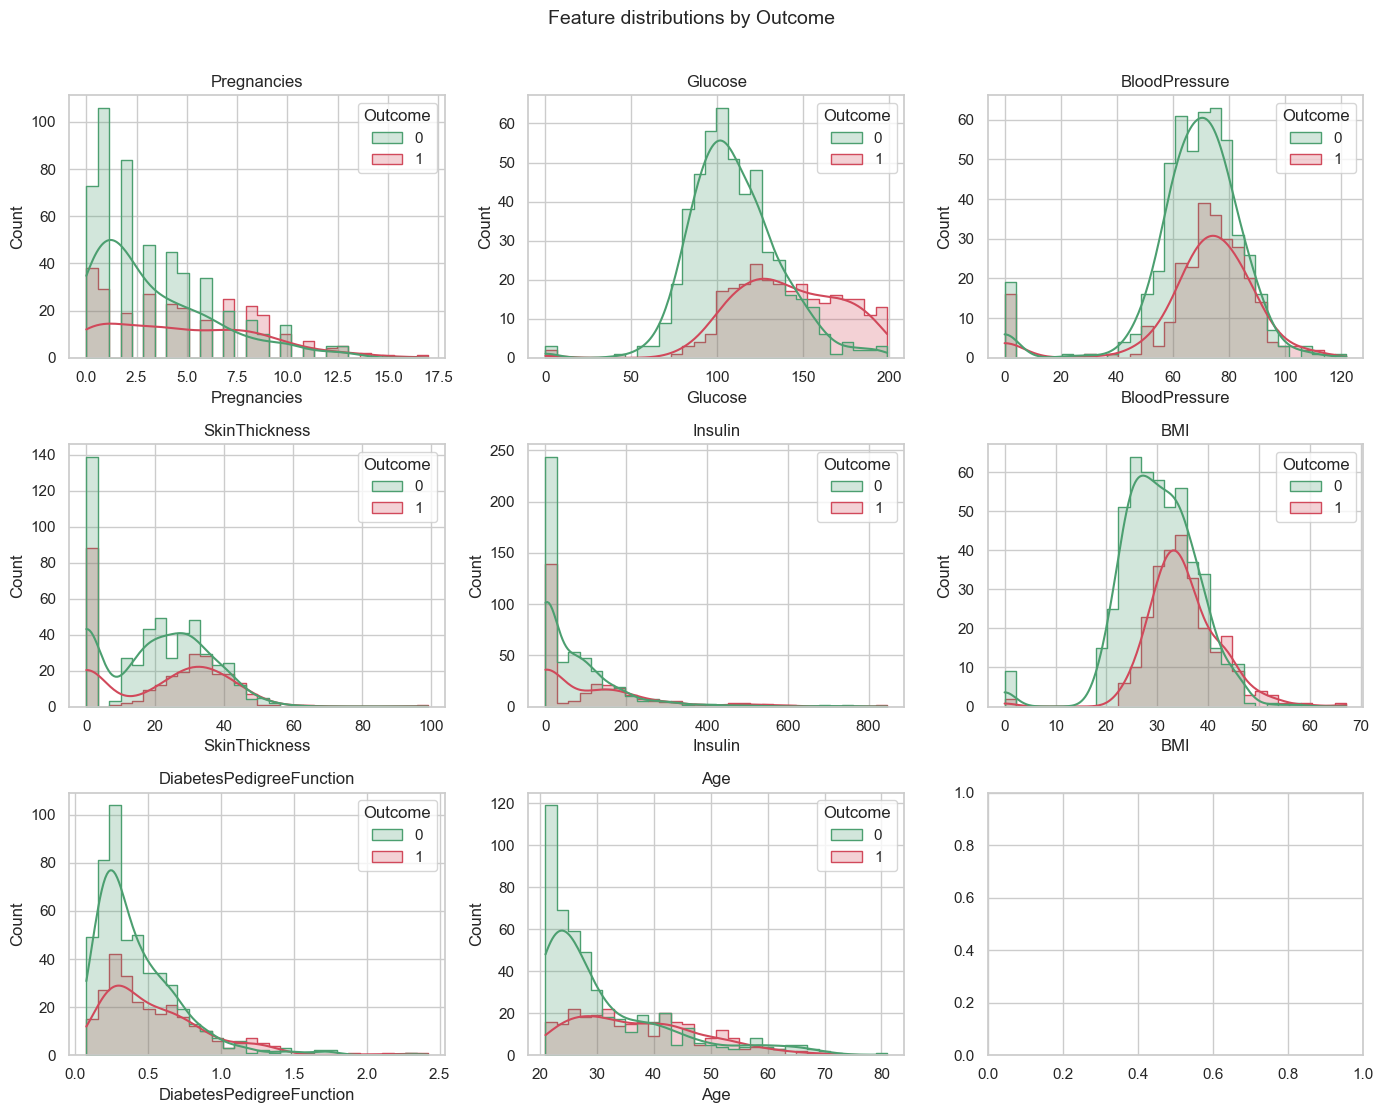

In [13]:
features = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, bins=30, ax=ax, palette=["#4C9F70", "#D1495B"], element="step")
    ax.set_title(col)
plt.suptitle("Feature distributions by Outcome", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### 2.5 Feature vs. target comparison and outliers

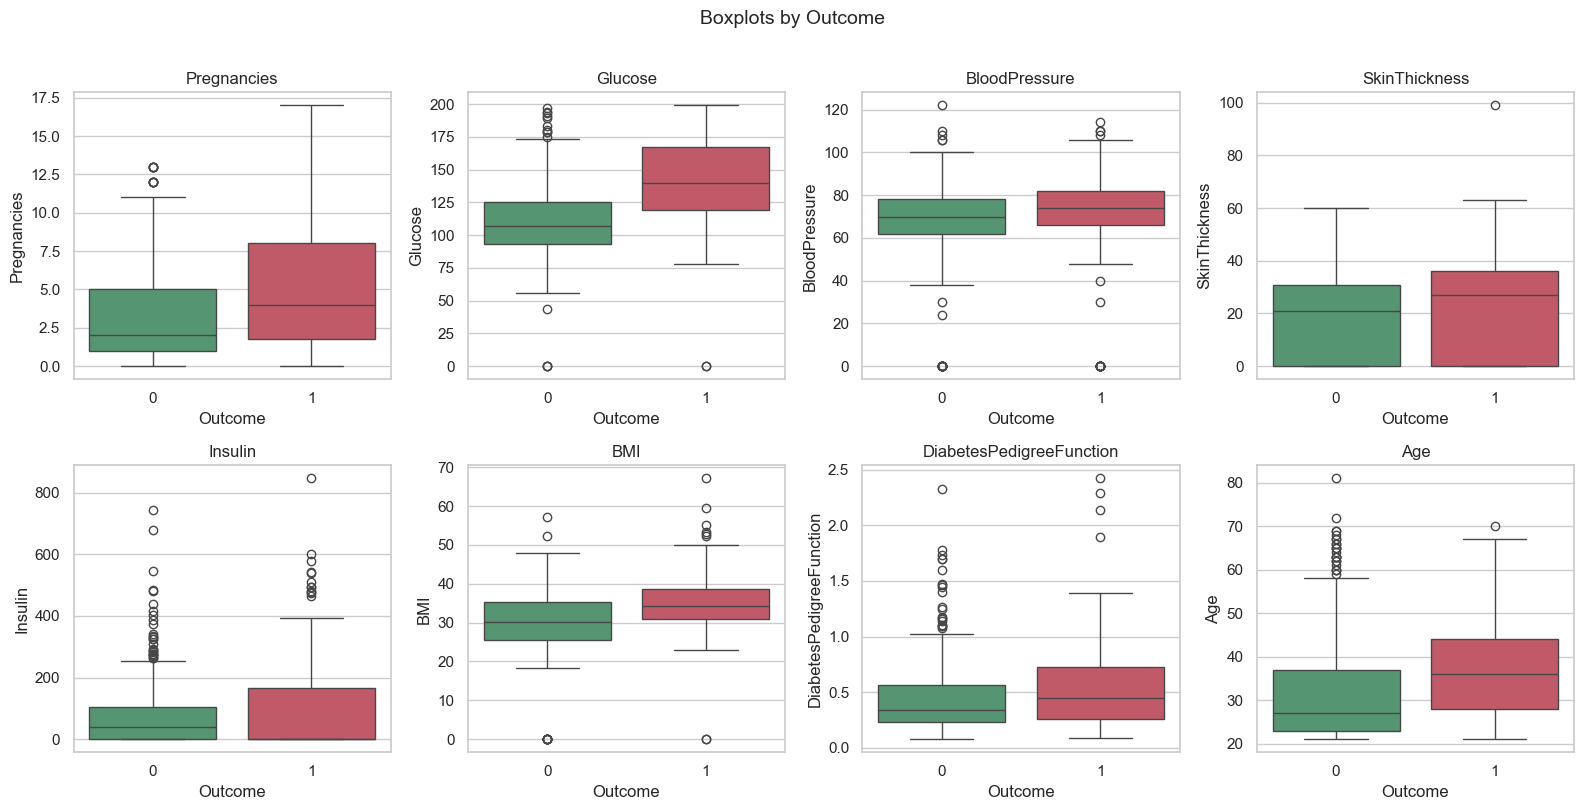

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax, palette=["#4C9F70", "#D1495B"])
    ax.set_title(col)
plt.suptitle("Boxplots by Outcome", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### 2.6 Correlation analysis

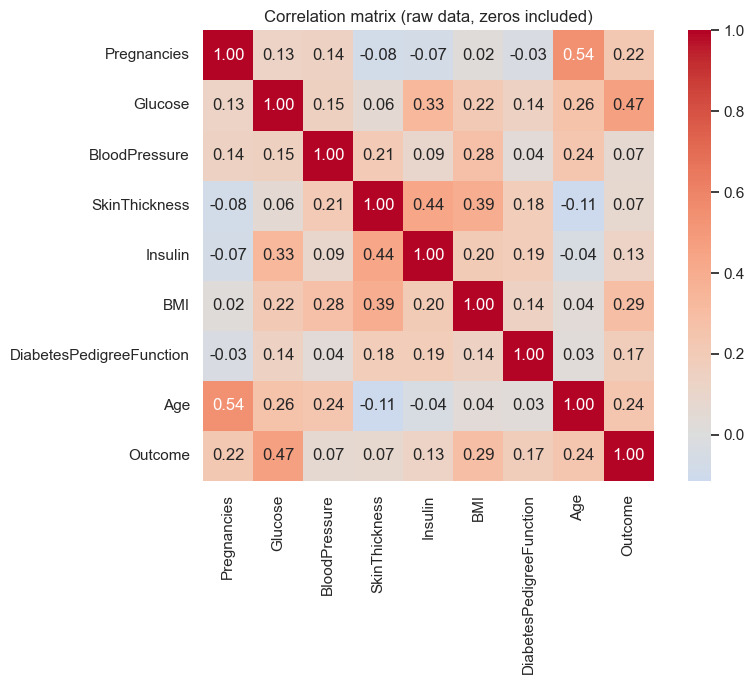

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


In [15]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (raw data, zeros included)")
plt.tight_layout(); plt.show()

print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

**EDA findings**
- Classes are imbalanced (500 non-diabetic vs. 268 diabetic, about 65% / 35%), so accuracy alone can be misleading. F1-score is therefore reported alongside accuracy.
- `Glucose`, `BMI` and `Age` show the strongest correlation with `Outcome` (0.47, 0.29, 0.24). Diabetic patients average 141 mg/dL glucose vs. 110 for non-diabetic, a BMI of 35.1 vs. 30.3, and an age of 37 vs. 31.
- `Insulin` and `SkinThickness` have many zeros, which distort their distributions and correlations. This justifies the cleaning step below.
- Some extreme values exist (e.g. `Insulin`, `DiabetesPedigreeFunction`, `Pregnancies`). These look like genuine clinical values, so they are kept.

### 2.7 Data cleaning
Zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` are converted to `NaN` so they are treated as missing values. They are imputed later with the **median** of the training set only, which avoids data leakage.

In [16]:
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

print("Missing values after replacing invalid zeros:")
print(df_clean.isna().sum()[zero_cols])
print(f"\nRows with at least one missing value: {df_clean.isna().any(axis=1).sum()} of {len(df_clean)}")

Missing values after replacing invalid zeros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Rows with at least one missing value: 376 of 768


### 2.8 Separate features (X) and target (y)

In [17]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


### 2.9 Train-test split
An 80/20 split with `stratify=y` keeps the same class ratio in both sets.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]} rows, {X_test.shape[1]} features")
print("\nClass ratio (Outcome=1) — train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Training set: 614 rows, 8 features
Testing set:  154 rows, 8 features

Class ratio (Outcome=1) — train: 0.349 | test: 0.351


### 2.10 Preprocessing steps
Preprocessing is wrapped in a `Pipeline`, so the imputer and scaler are fitted **only on the training data** and then applied to the test data.
1. **Missing values:** `SimpleImputer(strategy="median")` fills the zeros converted in 2.7.
2. **Encoding:** not required, because all features are numeric.
3. **Scaling:** `StandardScaler` standardizes features to mean 0 and standard deviation 1. This is needed for Logistic Regression, which is sensitive to feature scale.

## 3. Part 2 — Model Building

**Algorithm choice: Logistic Regression.** This is a supervised binary classifier that estimates the probability of the positive class with a sigmoid function of a weighted sum of features.

It suits this problem because:
- The target is binary (diabetic / not diabetic).
- The coefficients are interpretable, so clinicians can see which attributes push the risk up or down.
- It is a strong, fast baseline for small tabular medical datasets (768 rows, 8 features) and is less prone to overfitting than complex models.
- `class_weight="balanced"` is used to handle the imbalance in the target.

In [19]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
model

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


## 4. Part 3 — Model Training

### 4.1 Fit the model on the training data

In [20]:
model.fit(X_train, y_train)
print("Model trained on", len(X_train), "samples.")

Model trained on 614 samples.


### 4.2 Training predictions and training performance

In [21]:
y_train_pred = model.predict(X_train)

train_acc = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Training F1-Score: {train_f1:.4f}")

Training Accuracy: 0.7590
Training F1-Score: 0.6726


## 5. Part 4 — Model Evaluation on the Test Set

The test set was not used for training or preprocessing fitting. It is used only for the final evaluation.

In [22]:
y_test_pred = model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)

print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test F1-Score:  {test_f1:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")

Test Accuracy:  0.7338
Test F1-Score:  0.6496
Test Precision: 0.6032
Test Recall:    0.7037


In [23]:
print(classification_report(y_test, y_test_pred, target_names=["No diabetes (0)", "Diabetes (1)"], digits=4))

                 precision    recall  f1-score   support

No diabetes (0)     0.8242    0.7500    0.7853       100
   Diabetes (1)     0.6032    0.7037    0.6496        54

       accuracy                         0.7338       154
      macro avg     0.7137    0.7269    0.7175       154
   weighted avg     0.7467    0.7338    0.7377       154



### 5.1 Confusion matrix

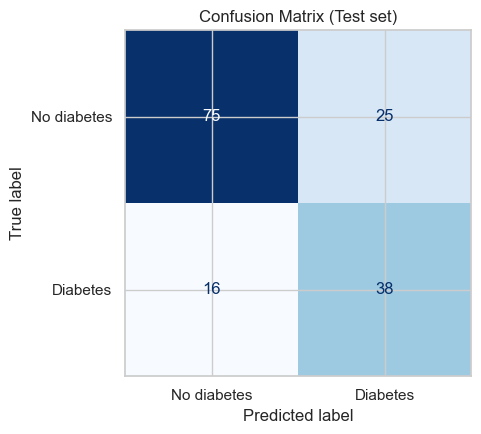

True Negatives: 75 | False Positives: 25 | False Negatives: 16 | True Positives: 38


In [24]:
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix (Test set)")
plt.tight_layout(); plt.show()

print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

## 6. Training vs. Testing Comparison

In [25]:
comparison = pd.DataFrame({
    "Training": [train_acc, train_f1],
    "Testing": [test_acc, test_f1],
}, index=["Accuracy", "F1-Score"])
comparison["Gap (Train - Test)"] = comparison["Training"] - comparison["Testing"]
comparison.round(4)

,Training,Testing,Gap (Train - Test)
Accuracy,0.7590,0.7338,0.0252
F1-Score,0.6726,0.6496,0.0230


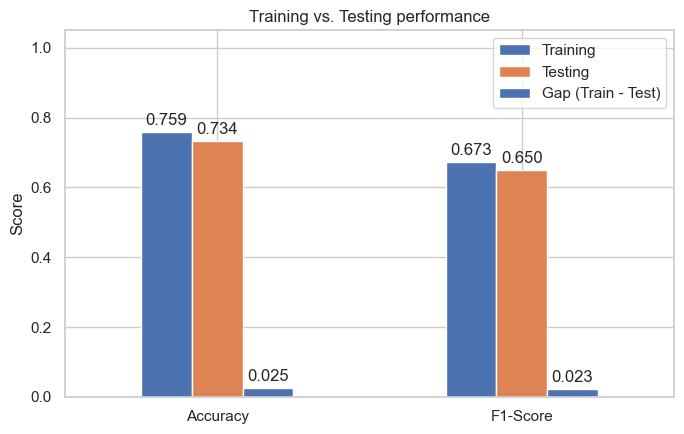

In [26]:
ax = comparison.plot(kind="bar", figsize=(7, 4.5), color=["#4C72B0", "#DD8452"], rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Training vs. Testing performance")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout(); plt.show()

### 6.1 Cross-validation check (robustness)

A single split can be lucky or unlucky, so a stratified 5-fold cross-validation on the training set is run to check how stable the scores are.

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "f1"])

cv_summary = pd.DataFrame({
    "Mean": [cv_results["test_accuracy"].mean(), cv_results["test_f1"].mean()],
    "Std": [cv_results["test_accuracy"].std(), cv_results["test_f1"].std()],
}, index=["Accuracy", "F1-Score"])
cv_summary.round(4)

,Mean,Std
Accuracy,0.7622,0.0111
F1-Score,0.6724,0.0133


## 7. Model Interpretation

Because features are standardized, the coefficient magnitudes can be compared directly. A positive coefficient raises the predicted probability of diabetes; a negative one lowers it.

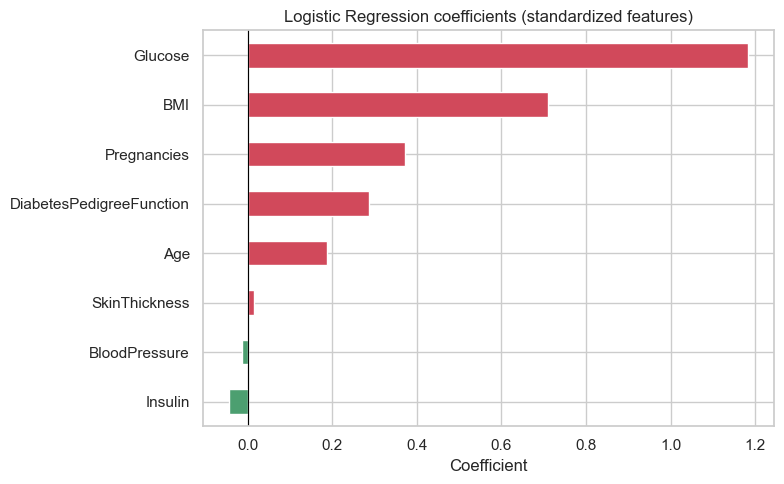

Glucose                     1.1835
BMI                         0.7096
Pregnancies                 0.3729
DiabetesPedigreeFunction    0.2877
Age                         0.1864
SkinThickness               0.0140
BloodPressure              -0.0146
Insulin                    -0.0446
dtype: float64

In [30]:
coef = pd.Series(model.named_steps["classifier"].coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
colors = ["#4C9F70" if v < 0 else "#D1495B" for v in coef]
coef.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression coefficients (standardized features)")
plt.xlabel("Coefficient")
plt.tight_layout(); plt.show()

coef.sort_values(ascending=False).round(4)

## 8. Conclusions and Business / Analytical Insights

**Model performance (test set)**
- **Test accuracy: 73.4%**, **test F1-score: 0.650** (precision 0.603, recall 0.704).
- **Training accuracy: 75.9%**, **training F1-score: 0.673**. The gap to test is only about 2.5 points, so the model is not overfitting.
- The 5-fold cross-validation on the training set gives accuracy 76.2% ± 1.1 and F1 0.672 ± 0.013. This agrees with the training and test results, so the test score is not a lucky split.
- Because the classes are imbalanced, the F1-score and the recall for the diabetic class (1) matter most. The model catches about 70% of diabetic patients (38 of 54 in the test set), and misses 16.

**Clinical interpretation**
- **False negatives** (diabetic patients predicted as healthy) are the costliest errors, since they delay diagnosis. Recall for class 1 is the metric to watch for this.
- **False positives** lead to extra screening, which is less harmful.
- The coefficients in Section 7 show that glucose and BMI are the strongest risk drivers, followed by pregnancies, pedigree function and age. This matches medical knowledge. Insulin, blood pressure and skin thickness contribute almost nothing once the other features are included.

**Limitations**
- The dataset is small (768 rows) and comes from a single population (Pima Indian women aged 21+), so results may not generalize to other groups.
- Imputing zeros with the median is a simple approach; more advanced imputation (e.g. KNN or regression) could be tested.
- Logistic Regression assumes a roughly linear relationship between features and log-odds. A tree-based model (e.g. Random Forest) could be compared as an extension.